# BankChurners Data Cleaning and Transformation
## Task 2

I use the BankChurners dataset to prepare customer records for attrition analysis. My work covers the data structure, column types, missing information, duplicate records, inconsistent category labels, invalid values, and outliers. I then create customer grouping fields and export the prepared dataset.

I keep the original records unchanged in a separate DataFrame. I explain what each code cell does and interpret its output. The numerical findings below refer to the supplied BankChurners file.

### Libraries used
- **pandas** reads, checks, transforms, and exports the data.
- **matplotlib** produces charts to help me inspect numerical distributions.
- **pathlib** handles file and output-folder locations.
- **IPython.display** displays tables inside Jupyter Notebook.

I use `dl` as the name of my working DataFrame. A DataFrame is a table with labelled rows and columns.

## 1 Import the libraries

I import the libraries needed for this preparation. The short name `pd` allows me to call pandas commands such as `pd.read_csv()`.

In [1]:
# Import the libraries used in this notebook.
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# Allow wider tables to show more columns in Jupyter.
pd.set_option('display.max_columns', 30)
pd.set_option('display.width', 160)
print('Libraries imported successfully.')

Libraries imported successfully.


**My interpretation**

The libraries are available. I can now read and inspect the customer data.

## 2 Read the dataset and preserve the original

I read the CSV into `dl`. I use `.copy()` to keep the original table separate, so later transformations do not overwrite it.

In [5]:
# Read the customer dataset from its file location.
file_path = Path(r"C:/Users/DEBIDO/Desktop/BankChurners.csv")
dl = pd.read_csv(file_path)

# Preserve the original table for later comparisons.
original_dl = dl.copy(deep=True)

# Create an output folder beside the source file.
output_folder = file_path.parent / 'Task2_Outputs'
output_folder.mkdir(exist_ok=True)

print('Dataset loaded successfully.')
print('Original records:', len(original_dl))
print('Original columns:', len(original_dl.columns))

Dataset loaded successfully.
Original records: 10127
Original columns: 23


**My interpretation**

The supplied file has 10,127 customer records and 23 columns. This is the starting point for my before-and-after comparison.

## 3 Remove the two precomputed classifier columns

The supplied dataset instruction says to exclude the final two Naive Bayes classifier columns. I identify them by their name prefix and remove them before analysing customer measurements.

In [6]:
# Find the two columns containing existing classifier outputs.
classifier_columns = [
    column for column in dl.columns
    if column.startswith('Naive_Bayes_Classifier_')
]

# Check the expected columns were found before removing them.
assert len(classifier_columns) == 2

# Remove only these columns from the working data.
dl = dl.drop(columns=classifier_columns)

print('Classifier columns removed:', len(classifier_columns))
print('Remaining columns:', dl.shape[1])

Classifier columns removed: 2
Remaining columns: 21


**My interpretation**

I removed two columns, leaving 21 source columns. These removed fields contain precomputed model outputs. Keeping them in a later model could give misleading performance. I did not remove any customer records.

## 4 Preview the first five records

`dl.head()` displays the first five rows. It helps me see how the records and fields are arranged; it does not check every record.

In [7]:
# View the first five customer records.
display(dl.head())

,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000


**My interpretation**

The preview contains customer identifiers, customer status, demographic information, and credit card usage fields. Each row is one customer record. `head()` previews rows, while `shape` in the next cell gives the full row and column counts.

## 5 Inspect the table size and column names

I use `.shape` for the number of rows and columns. I use `.columns` to see the field names.

In [8]:
# The first shape value is rows; the second is columns.
print('Customer records:', dl.shape[0])
print('Working columns:', dl.shape[1])

# List all remaining source fields.
print('\nColumn names:')
for column in dl.columns:
    print(column)

Customer records: 10127
Working columns: 21

Column names:
CLIENTNUM
Attrition_Flag
Customer_Age
Gender
Dependent_count
Education_Level
Marital_Status
Income_Category
Card_Category
Months_on_book
Total_Relationship_Count
Months_Inactive_12_mon
Contacts_Count_12_mon
Credit_Limit
Total_Revolving_Bal
Avg_Open_To_Buy
Total_Amt_Chng_Q4_Q1
Total_Trans_Amt
Total_Trans_Ct
Total_Ct_Chng_Q4_Q1
Avg_Utilization_Ratio


**My interpretation**

The working table contains 10,127 customers and 21 columns. Fields such as Total_Trans_Ct, Credit_Limit, and Avg_Utilization_Ratio can support later comparisons between existing and attrited customers.

## 6 Inspect data types

`dl.info()` shows each field’s type and the number of populated values. Whole numbers usually appear as `int64`, decimal numbers as `float64`, and text fields as `object`.

In [9]:
# Inspect types and populated counts for all working columns.
dl.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10127 entries, 0 to 10126
Data columns (total 21 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CLIENTNUM                 10127 non-null  int64  
 1   Attrition_Flag            10127 non-null  object 
 2   Customer_Age              10127 non-null  int64  
 3   Gender                    10127 non-null  object 
 4   Dependent_count           10127 non-null  int64  
 5   Education_Level           10127 non-null  object 
 6   Marital_Status            10127 non-null  object 
 7   Income_Category           10127 non-null  object 
 8   Card_Category             10127 non-null  object 
 9   Months_on_book            10127 non-null  int64  
 10  Total_Relationship_Count  10127 non-null  int64  
 11  Months_Inactive_12_mon    10127 non-null  int64  
 12  Contacts_Count_12_mon     10127 non-null  int64  
 13  Credit_Limit              10127 non-null  float64
 14  Total_

**My interpretation**

All 21 working columns contain 10,127 populated entries. CLIENTNUM is initially stored as a whole number, but it identifies a customer rather than measuring a quantity. I will store it as text. A populated entry can still be Unknown, so I check that separately.

## 7 Check blank cells

`.isna()` identifies blank or missing values. Adding `.sum()` counts those values in each column.

In [10]:
# Count genuine blank values in each column.
blank_values = dl.isna().sum()
display(blank_values.to_frame('Blank_cells'))

print('Total blank cells:', blank_values.sum())

,Blank_cells
CLIENTNUM,0
Attrition_Flag,0
Customer_Age,0
Gender,0
Dependent_count,0
Education_Level,0
Marital_Status,0
Income_Category,0
Card_Category,0
Months_on_book,0


Total blank cells: 0


**My interpretation**

There are no blank cells. I therefore do not need to fill blanks with an average, median, or most common category. I still need to examine explicit Unknown values because they represent unavailable information.

## 8 Check Unknown demographic information

I examine education, marital status, and income separately. I also count customers with at least one Unknown value, since one customer may have more than one.

In [11]:
# Select the demographic fields that may contain Unknown.
unknown_fields = ['Education_Level', 'Marital_Status', 'Income_Category']

# Count Unknown entries in each selected field.
unknown_counts = dl[unknown_fields].eq('Unknown').sum()
unknown_table = unknown_counts.to_frame('Unknown_count')
unknown_table['Percentage_of_customers'] = (
    unknown_counts / len(dl) * 100
).round(2)
display(unknown_table)

# any(axis=1) checks whether a customer has Unknown in any selected field.
unknown_customers = dl[unknown_fields].eq('Unknown').any(axis=1).sum()
print('Customers with at least one Unknown value:', unknown_customers)

,Unknown_count,Percentage_of_customers
Education_Level,1519,15.00
Marital_Status,749,7.40
Income_Category,1112,10.98


Customers with at least one Unknown value: 3046


**My interpretation**

Education has 1,519 Unknown entries (15.00%), marital status has 749 (7.40%), and income has 1,112 (10.98%). These affect 3,046 distinct customers. I retain Unknown as a category because assigning a guessed income, education level, or marital status would introduce unsupported information.

## 9 Check duplicate records

I check for repeated complete rows and repeated customer IDs. These are different checks: two records can share an identifier while containing different information.

In [12]:
# Count identical customer rows.
duplicate_rows = dl.duplicated().sum()

# Count repeated customer identifiers.
duplicate_ids = dl['CLIENTNUM'].duplicated().sum()
missing_ids = dl['CLIENTNUM'].isna().sum()

print('Duplicate rows:', duplicate_rows)
print('Duplicate customer IDs:', duplicate_ids)
print('Missing customer IDs:', missing_ids)

Duplicate rows: 0
Duplicate customer IDs: 0
Missing customer IDs: 0


**My interpretation**

There are no duplicate rows, repeated customer IDs, or missing customer IDs. I therefore keep every customer record. Removing duplicates is unnecessary in this file.

## 10 Inspect category labels

I display the observed labels and counts for every text field. This helps identify spelling differences, inconsistent capitalisation, or categories that need investigation.

In [13]:
# Identify the text columns in the current dataset.
text_columns = dl.select_dtypes(include='object').columns.tolist()

# Display every observed label and its customer count.
for column in text_columns:
    print('\n' + column)
    display(dl[column].value_counts(dropna=False).to_frame('Customers'))

# Check whether any text values contain surrounding spaces.
space_counts = {}
for column in text_columns:
    space_counts[column] = (
        dl[column] != dl[column].str.strip()
    ).sum()

display(pd.Series(space_counts, name='Values_with_extra_spaces').to_frame())


Attrition_Flag


,Customers
Attrition_Flag,
Existing Customer,8500
Attrited Customer,1627



Gender


,Customers
Gender,
F,5358
M,4769



Education_Level


,Customers
Education_Level,
Graduate,3128
High School,2013
Unknown,1519
Uneducated,1487
College,1013
Post-Graduate,516
Doctorate,451


... (3 outputs left out)

,Customers
Income_Category,
Less than $40K,3561
$40K - $60K,1790
$80K - $120K,1535
$60K - $80K,1402
Unknown,1112
$120K +,727



Card_Category


,Customers
Card_Category,
Blue,9436
Silver,555
Gold,116
Platinum,20


,Values_with_extra_spaces
Attrition_Flag,0
Gender,0
Education_Level,0
Marital_Status,0
Income_Category,0
Card_Category,0


**My interpretation**

The displayed labels contain no observed spelling or capitalisation variants requiring merging. There are also no surrounding-space issues. Unknown is an explicit category, not a spelling error. I retain distinct education labels such as College and Graduate. This review assesses consistency within the file, not external accuracy.

## 11 Summarise numerical measurements

`.describe()` gives the count, mean, standard deviation, minimum, quartiles, and maximum. I exclude CLIENTNUM because its average has no business meaning.

In [14]:
# Select numeric customer measurements, excluding the identifier.
numeric_columns = dl.select_dtypes(include='number').columns.tolist()
numeric_columns.remove('CLIENTNUM')

# Transpose the table so each measurement appears on one row.
numeric_summary = dl[numeric_columns].describe().T
display(numeric_summary.round(3))

,count,mean,std,min,25%,50%,75%,max
Customer_Age,10127.0,46.326,8.017,26.0,41.000,46.000,52.000,73.000
Dependent_count,10127.0,2.346,1.299,0.0,1.000,2.000,3.000,5.000
Months_on_book,10127.0,35.928,7.986,13.0,31.000,36.000,40.000,56.000
Total_Relationship_Count,10127.0,3.813,1.554,1.0,3.000,4.000,5.000,6.000
Months_Inactive_12_mon,10127.0,2.341,1.011,0.0,2.000,2.000,3.000,6.000
Contacts_Count_12_mon,10127.0,2.455,1.106,0.0,2.000,2.000,3.000,6.000
Credit_Limit,10127.0,8631.954,9088.777,1438.3,2555.000,4549.000,11067.500,34516.000
Total_Revolving_Bal,10127.0,1162.814,814.987,0.0,359.000,1276.000,1784.000,2517.000
Avg_Open_To_Buy,10127.0,7469.140,9090.685,3.0,1324.500,3474.000,9859.000,34516.000
Total_Amt_Chng_Q4_Q1,10127.0,0.760,0.219,0.0,0.631,0.736,0.859,3.397


**My interpretation**

Ages range from 26 to 73. Credit limits range from 1,438.30 to 34,516, and transaction amounts range from 510 to 18,484 in the original monetary units. These wide ranges justify inspecting unusual values. They do not, by themselves, establish errors. Zero utilisation or revolving balance can also be legitimate.

## 12 Check numerical validity

I check broad plausibility rules. Counts should be nonnegative whole numbers; inactive months should be between 0 and 12; utilisation should be between 0 and 1. The age range of 18 to 110 is a broad screening choice, not a documented eligibility rule.

In [15]:
# Identify fields representing whole-number counts.
count_columns = [
    'Dependent_count', 'Months_on_book', 'Total_Relationship_Count',
    'Months_Inactive_12_mon', 'Contacts_Count_12_mon', 'Total_Trans_Ct'
]

# The remainder after division by 1 should be zero for whole numbers.
fractional_counts = (dl[count_columns] % 1 != 0).any(axis=1).sum()

# Build a readable table of numerical validity checks.
invalid_values = pd.Series({
    'Negative numeric measurements': (dl[numeric_columns] < 0).sum().sum(),
    'Ages outside 18 to 110': (~dl['Customer_Age'].between(18, 110)).sum(),
    'Noninteger ages': (dl['Customer_Age'] % 1 != 0).sum(),
    'Records with fractional counts': fractional_counts,
    'Nonpositive credit limits': (dl['Credit_Limit'] <= 0).sum(),
    'Inactive months outside 0 to 12':
        (~dl['Months_Inactive_12_mon'].between(0, 12)).sum(),
    'Utilisation outside 0 to 1':
        (~dl['Avg_Utilization_Ratio'].between(0, 1)).sum(),
    'Revolving balances above credit limits':
        (dl['Total_Revolving_Bal'] > dl['Credit_Limit']).sum()
}, name='Flagged_values_or_records')

display(invalid_values.to_frame())
assert invalid_values.eq(0).all(), 'Review flagged numerical values.'

,Flagged_values_or_records
Negative numeric measurements,0
Ages outside 18 to 110,0
Noninteger ages,0
Records with fractional counts,0
Nonpositive credit limits,0
Inactive months outside 0 to 12,0
Utilisation outside 0 to 1,0
Revolving balances above credit limits,0


**My interpretation**

Every implemented rule returned zero flagged values or records. No numerical correction is justified by these checks. They identify obvious contradictions but cannot independently verify every recorded value.

## 13 Check consistency between related fields

I check that available credit equals credit limit minus revolving balance. I also compare recorded utilisation with revolving balance divided by credit limit. Small tolerances allow for decimal rounding.

In [16]:
# Check the available-credit relationship.
credit_difference = (
    dl['Credit_Limit'] - dl['Total_Revolving_Bal'] - dl['Avg_Open_To_Buy']
).abs()

# Check the utilisation relationship.
calculated_utilisation = dl['Total_Revolving_Bal'] / dl['Credit_Limit']
utilisation_difference = (
    calculated_utilisation - dl['Avg_Utilization_Ratio']
).abs()

consistency_checks = pd.Series({
    'Available credit differences above 0.01': (credit_difference > 0.01).sum(),
    'Utilisation differences above 0.00051': (utilisation_difference > 0.00051).sum()
}, name='Flagged_records')

display(consistency_checks.to_frame())
assert consistency_checks.eq(0).all(), 'Review inconsistent records.'

,Flagged_records
Available credit differences above 0.01,0
Utilisation differences above 0.00051,0


**My interpretation**

No records fail these reconciliation checks. The utilisation tolerance allows for the source ratios being rounded to three decimal places. I retain the original values rather than replace them with unnecessarily recalculated figures.

## 14 Identify potential outliers

I use the interquartile range (IQR) as a screening method. Q1 and Q3 are the 25th and 75th percentiles. I flag values below Q1 minus 1.5 times IQR or above Q3 plus 1.5 times IQR. A flag means unusual, not necessarily incorrect.

In [17]:
# Calculate an IQR screen for each numeric customer measurement.
outlier_rows = []

for column in numeric_columns:
    q1 = dl[column].quantile(0.25)
    q3 = dl[column].quantile(0.75)
    iqr = q3 - q1

    lower_fence = q1 - 1.5 * iqr
    upper_fence = q3 + 1.5 * iqr
    flagged = (dl[column] < lower_fence) | (dl[column] > upper_fence)

    outlier_rows.append({
        'Field': column,
        'Lower_fence': lower_fence,
        'Upper_fence': upper_fence,
        'Flagged_records': flagged.sum(),
        'Flagged_percentage': round(flagged.mean() * 100, 2)
    })

outlier_table = pd.DataFrame(outlier_rows)
display(outlier_table.round(3))

,Field,Lower_fence,Upper_fence,Flagged_records,Flagged_percentage
0,Customer_Age,24.500,68.500,2,0.02
1,Dependent_count,-2.000,6.000,0,0.00
2,Months_on_book,17.500,53.500,386,3.81
3,Total_Relationship_Count,0.000,8.000,0,0.00
4,Months_Inactive_12_mon,0.500,4.500,331,3.27
5,Contacts_Count_12_mon,0.500,4.500,629,6.21
6,Credit_Limit,-10213.750,23836.250,984,9.72
7,Total_Revolving_Bal,-1778.500,3921.500,0,0.00
8,Avg_Open_To_Buy,-11477.250,22660.750,963,9.51
9,Total_Amt_Chng_Q4_Q1,0.289,1.201,396,3.91


**My interpretation**

The screen flags 984 credit limits and 896 transaction amounts. It also flags some ages, tenure values, inactivity counts, and other measurements. Since these values pass the implemented validity checks, I retain them. For bounded count fields and uneven distributions, IQR flags require particular caution. I do not cap or delete values simply to reduce outlier counts.

## 15 Inspect the distributions visually

Histograms show how customers are distributed across credit limits and transaction amounts. Each bar counts customers within a range of values.

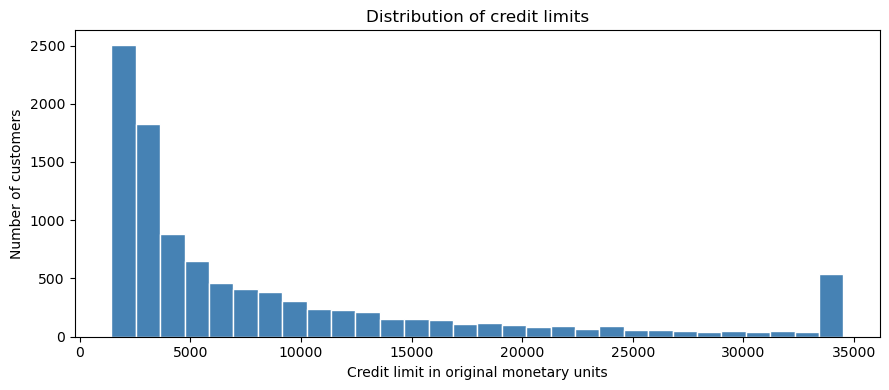

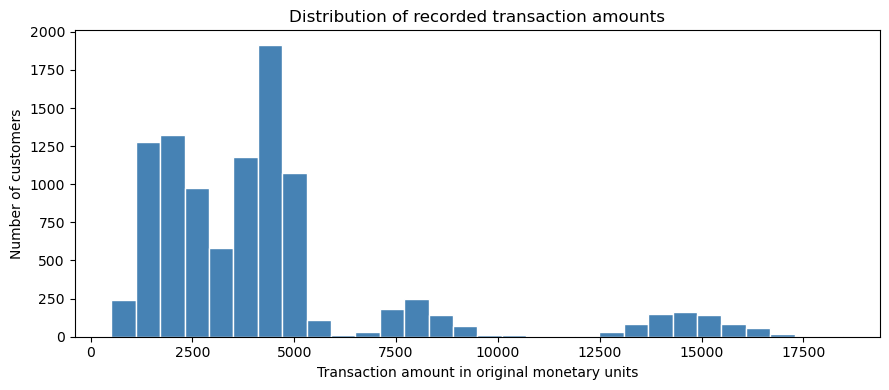

In [18]:
# Show the credit-limit distribution.
plt.figure(figsize=(9, 4))
plt.hist(dl['Credit_Limit'], bins=30, color='steelblue', edgecolor='white')
plt.title('Distribution of credit limits')
plt.xlabel('Credit limit in original monetary units')
plt.ylabel('Number of customers')
plt.tight_layout()
plt.savefig(output_folder / 'Credit_Limit_Distribution.png', dpi=150)
plt.show()

# Show the transaction-amount distribution.
plt.figure(figsize=(9, 4))
plt.hist(dl['Total_Trans_Amt'], bins=30, color='steelblue', edgecolor='white')
plt.title('Distribution of recorded transaction amounts')
plt.xlabel('Transaction amount in original monetary units')
plt.ylabel('Number of customers')
plt.tight_layout()
plt.savefig(output_folder / 'Transaction_Amount_Distribution.png', dpi=150)
plt.show()

**My interpretation**

Credit limits concentrate toward the lower end, with some customers near the maximum. Transaction amounts have several clusters rather than a single symmetric shape. These patterns help explain why an IQR screen flags some high observations. The plots support retaining the values for further analysis, while recognising that source verification would be needed to prove their accuracy.

## 16 Standardise labels and the identifier

I trim surrounding spaces and store CLIENTNUM as text. The space check found no affected values, so trimming is preventive standardisation, not a claim that errors were corrected.

In [19]:
# Standardise text labels without merging legitimate categories.
for column in text_columns:
    dl[column] = dl[column].str.strip()

# Store customer identifiers as text rather than numerical measurements.
dl['CLIENTNUM'] = dl['CLIENTNUM'].astype(str)

print('CLIENTNUM type after conversion:', dl['CLIENTNUM'].dtype)
print('Customer records retained:', len(dl))
print('No numeric source measurements were changed.')

CLIENTNUM type after conversion: object
Customer records retained: 10127
No numeric source measurements were changed.


**My interpretation**

CLIENTNUM is now stored as text (shown as object in pandas). I have kept all 10,127 customer records, all Unknown categories, legitimate zeros, and numerical extremes. There were no blank values to impute and no duplicated records to remove.

## 17 Create age bands

I create five age groups to make comparisons easier. With `right=False`, each lower boundary is included: age 35 belongs to 35 to 44, while age 45 belongs to 45 to 54.

In [20]:
# Group ages while retaining the original Customer_Age column.
dl['Age_Band'] = pd.cut(
    dl['Customer_Age'],
    bins=[0, 35, 45, 55, 65, float('inf')],
    labels=['Under 35', '35 to 44', '45 to 54', '55 to 64', '65 and above'],
    right=False
)

display(dl['Age_Band'].value_counts(sort=False).to_frame('Customers'))

,Customers
Age_Band,
Under 35,735
35 to 44,3440
45 to 54,4342
55 to 64,1499
65 and above,111


**My interpretation**

There are 735 customers under 35, 3,440 aged 35 to 44, 4,342 aged 45 to 54, 1,499 aged 55 to 64, and 111 aged 65 and above. These are descriptive groups, not risk levels. The original ages remain available.

## 18 Create broader income segments

I combine adjacent source income categories without estimating exact income. I retain Unknown separately and keep the original dollar labels.

In [21]:
# Map the detailed income categories to broader segments.
income_mapping = {
    'Less than $40K': 'Below $40K',
    '$40K - $60K': '$40K to below $80K',
    '$60K - $80K': '$40K to below $80K',
    '$80K - $120K': '$80K and above',
    '$120K +': '$80K and above',
    'Unknown': 'Unknown'
}

dl['Income_Segment'] = dl['Income_Category'].map(income_mapping)
display(dl['Income_Segment'].value_counts().to_frame('Customers'))

,Customers
Income_Segment,
Below $40K,3561
$40K to below $80K,3192
$80K and above,2262
Unknown,1112


**My interpretation**

The resulting counts are 3,561 below $40K, 3,192 from $40K to below $80K, 2,262 at $80K and above, and 1,112 Unknown. These wider groups simplify comparison. I retain the original Income_Category field and do not convert these labels to naira.

## 19 Create utilisation categories

I use clearly defined descriptive thresholds. Zero means exactly 0; Low means more than 0 but below 0.30; Moderate means 0.30 to below 0.60; High means 0.60 to 1. These groups describe usage, not creditworthiness or validated churn risk.

In [22]:
# Begin with High, then assign the lower utilisation groups.
dl['Utilization_Category'] = 'High'

dl.loc[dl['Avg_Utilization_Ratio'] < 0.60, 'Utilization_Category'] = 'Moderate'
dl.loc[dl['Avg_Utilization_Ratio'] < 0.30, 'Utilization_Category'] = 'Low'
dl.loc[dl['Avg_Utilization_Ratio'] == 0, 'Utilization_Category'] = 'Zero'

# Display the categories in a meaningful order.
display(
    dl['Utilization_Category'].value_counts()
    .reindex(['Zero', 'Low', 'Moderate', 'High'])
    .to_frame('Customers')
)

,Customers
Utilization_Category,
Zero,2470
Low,3776
Moderate,2066
High,1815


**My interpretation**

There are 2,470 customers with zero recorded utilisation, 3,776 in Low, 2,066 in Moderate, and 1,815 in High. A value of 0.30 enters Moderate and 0.60 enters High. These boundaries are practical grouping choices that I will assess in later analysis.

## 20 Create transaction frequency categories

I group customers by their recorded transaction count: Low below 50, Moderate from 50 to 79, and High at 80 or more. These fixed thresholds are descriptive choices, not established churn cut-offs or monthly transaction rates.

In [23]:
# Create simple transaction count groups.
dl['Transaction_Frequency_Category'] = 'High'
dl.loc[dl['Total_Trans_Ct'] < 80, 'Transaction_Frequency_Category'] = 'Moderate'
dl.loc[dl['Total_Trans_Ct'] < 50, 'Transaction_Frequency_Category'] = 'Low'

display(
    dl['Transaction_Frequency_Category'].value_counts()
    .reindex(['Low', 'Moderate', 'High'])
    .to_frame('Customers')
)

,Customers
Transaction_Frequency_Category,
Low,3037
Moderate,4367
High,2723


**My interpretation**

The groups contain 3,037 Low, 4,367 Moderate, and 2,723 High transaction-count customers. A count of 50 enters Moderate and 80 enters High. I retain the original transaction counts for more detailed comparisons.

## 21 Create the recorded churn flag

I convert the existing status labels into numbers: 1 means Attrited Customer and 0 means Existing Customer. This field records the known outcome; it is not a prediction.

In [24]:
# Convert the observed status into a numeric outcome flag.
dl['Churn_Flag'] = dl['Attrition_Flag'].map({
    'Existing Customer': 0,
    'Attrited Customer': 1
})

display(dl['Churn_Flag'].value_counts().sort_index().to_frame('Customers'))

,Customers
Churn_Flag,
0,8500
1,1627


**My interpretation**

The flag identifies 8,500 existing customers and 1,627 attrited customers, matching the source labels. I will not use Churn_Flag as an input when predicting that same outcome, because doing so would reveal the answer to the model.

## 22 Flag unavailable demographic information

I add a flag for customers with at least one Unknown value in education, marital status, or income. This makes missing information visible without replacing it.

In [25]:
# Check the three source demographic fields for each customer.
dl['Has_Unknown_Demographics'] = (
    dl[unknown_fields].eq('Unknown').any(axis=1).astype(int)
)

display(
    dl['Has_Unknown_Demographics'].value_counts().sort_index()
    .to_frame('Customers')
)

,Customers
Has_Unknown_Demographics,
0,7081
1,3046


**My interpretation**

The flag is 1 for 3,046 customers and 0 for 7,081 customers. It describes information availability, not customer quality. I have now added six analytical fields. I have not invented customer profitability or future churn probabilities.

## 23 Verify the transformations

I check that the source measurements are unchanged and that the new fields are complete. An assertion stops execution if its condition is false. This gives a clear failure rather than silently exporting incorrect data.

In [26]:
# List the six analytical fields added during preparation.
new_fields = [
    'Age_Band', 'Income_Segment', 'Utilization_Category',
    'Transaction_Frequency_Category', 'Churn_Flag',
    'Has_Unknown_Demographics'
]

# Confirm that all original numeric measurements remain identical.
pd.testing.assert_frame_equal(
    original_dl[numeric_columns],
    dl[numeric_columns]
)

# Confirm that original category values are preserved apart from trimming.
for column in text_columns:
    assert dl[column].equals(original_dl[column].str.strip())

# Confirm records, new groups, identifiers, and churn counts.
assert len(dl) == len(original_dl)
assert dl['CLIENTNUM'].is_unique
assert dl[new_fields].notna().all().all()
assert dl['Churn_Flag'].sum() == original_dl['Attrition_Flag'].eq('Attrited Customer').sum()
assert dl.shape[1] == original_dl.shape[1] - 2 + len(new_fields)

print('All transformation checks passed.')
print('Customer records:', len(dl))
print('Final columns:', dl.shape[1])

All transformation checks passed.
Customer records: 10127
Final columns: 27


**My interpretation**

All checks passed. The final table has 10,127 records and 27 columns: 23 original columns, minus two classifier outputs, plus six analytical fields. Original numeric measurements and category values are preserved. The earlier numerical validity results therefore still apply after transformation; the outlier flags also remain unchanged.

## 24 Compare data quality before and after

I place the key quality checks side by side. Unchanged Unknown counts are intentional because I did not guess replacements. A higher column count reflects new analytical fields, not extra source records.

In [27]:
# Build a before-and-after evidence table using the same definitions.
before_after = pd.DataFrame({
    'Check': [
        'Customer records', 'Columns', 'Blank cells', 'Duplicate rows',
        'Duplicate customer IDs', 'Unknown source demographic cells',
        'Customers with any Unknown', 'Precomputed classifier columns'
    ],
    'Before': [
        len(original_dl), original_dl.shape[1],
        original_dl.isna().sum().sum(), original_dl.duplicated().sum(),
        original_dl['CLIENTNUM'].duplicated().sum(),
        original_dl[unknown_fields].eq('Unknown').sum().sum(),
        original_dl[unknown_fields].eq('Unknown').any(axis=1).sum(),
        len(classifier_columns)
    ],
    'After': [
        len(dl), dl.shape[1], dl.isna().sum().sum(), dl.duplicated().sum(),
        dl['CLIENTNUM'].duplicated().sum(),
        dl[unknown_fields].eq('Unknown').sum().sum(),
        dl[unknown_fields].eq('Unknown').any(axis=1).sum(),
        0
    ]
})

display(before_after)

,Check,Before,After
0,Customer records,10127,10127
1,Columns,23,27
2,Blank cells,0,0
3,Duplicate rows,0,0
4,Duplicate customer IDs,0,0
5,Unknown source demographic cells,3380,3380
6,Customers with any Unknown,3046,3046
7,Precomputed classifier columns,2,0


**My interpretation**

Customer records remain at 10,127, and blank cells, duplicate rows, and repeated IDs remain at zero. The three demographic fields contain 3,380 Unknown entries across 3,046 customers before and after preparation. Two classifier columns were removed, while six derived fields increased the final column count to 27.

## 25 Record the preparation decisions

I document each action and its reason. This explains why I retained some values instead of making unnecessary changes.

In [28]:
# Keep a concise record of what I changed or deliberately retained.
cleaning_decisions = pd.DataFrame({
    'Area': [
        'Blank cells', 'Unknown demographics', 'Duplicate records',
        'Invalid values', 'Outliers', 'Category labels',
        'Classifier outputs', 'Customer ID', 'Analytical fields'
    ],
    'Action and reason': [
        'No imputation because no blank cells were found.',
        'Retained Unknown; added a flag rather than guess personal information.',
        'No removal because rows and customer IDs were unique.',
        'No numeric correction because implemented validity checks passed.',
        'Retained IQR flags because statistical extremeness is not proof of error.',
        'Trimmed surrounding spaces; no observed values needed correction.',
        'Removed two precomputed model-output columns.',
        'Converted CLIENTNUM to text because it is an identifier.',
        'Added six documented fields for grouping and later analysis.'
    ]
})

display(cleaning_decisions)

,Area,Action and reason
0,Blank cells,No imputation because no blank cells were found.
1,Unknown demographics,Retained Unknown; added a flag rather than gue...
2,Duplicate records,No removal because rows and customer IDs were ...
3,Invalid values,No numeric correction because implemented vali...
4,Outliers,Retained IQR flags because statistical extreme...
5,Category labels,Trimmed surrounding spaces; no observed values...
6,Classifier outputs,Removed two precomputed model-output columns.
7,Customer ID,Converted CLIENTNUM to text because it is an i...
8,Analytical fields,Added six documented fields for grouping and l...


**My interpretation**

The main preparation changes are removing classifier outputs, storing the identifier as text, and adding analytical fields. I did not remove customers or alter numeric source values simply to make the file appear cleaner.

## 26 Document the new field definitions

I record the exact grouping rules so the customer categories can be reproduced and understood when used in Power BI.

In [29]:
# Save the meaning and boundaries of each new field.
field_definitions = pd.DataFrame({
    'Field': new_fields,
    'Definition': [
        'Under 35; 35 to 44; 45 to 54; 55 to 64; 65 and above.',
        'Below $40K; $40K to below $80K; $80K and above; Unknown.',
        'Zero = 0; Low > 0 and < 0.30; Moderate >= 0.30 and < 0.60; High >= 0.60 and <= 1.',
        'Low < 50; Moderate 50 to 79; High >= 80 recorded transactions.',
        'Observed outcome: Existing Customer = 0; Attrited Customer = 1.',
        '1 if any source education, marital status, or income is Unknown; otherwise 0.'
    ]
})

display(field_definitions)

,Field,Definition
0,Age_Band,Under 35; 35 to 44; 45 to 54; 55 to 64; 65 and...
1,Income_Segment,Below $40K; $40K to below $80K; $80K and above...
2,Utilization_Category,Zero = 0; Low > 0 and < 0.30; Moderate >= 0.30...
3,Transaction_Frequency_Category,Low < 50; Moderate 50 to 79; High >= 80 record...
4,Churn_Flag,Observed outcome: Existing Customer = 0; Attri...
5,Has_Unknown_Demographics,"1 if any source education, marital status, or ..."


**My interpretation**

The definitions make the category boundaries explicit. These fields describe age, income, usage, recorded status, and information availability. They should not be interpreted as validated risk levels or measures of profitability.

## 27 Export the cleaned dataset and quality evidence

I save the prepared CSV and the tables supporting my decisions. `index=False` prevents an unnecessary row-number column being added to the exported file.

In [30]:
# Export the prepared data.
cleaned_file = output_folder / 'BankChurners_Cleaned.csv'
dl.to_csv(cleaned_file, index=False)

# Export evidence of the checks and preparation decisions.
before_after.to_csv(output_folder / 'Before_After_Quality.csv', index=False)
unknown_table.to_csv(output_folder / 'Unknown_Information.csv', index_label='Field')
invalid_values.to_csv(output_folder / 'Numeric_Validity_Checks.csv', header=True)
consistency_checks.to_csv(output_folder / 'Field_Consistency_Checks.csv', header=True)
outlier_table.to_csv(output_folder / 'Outlier_Audit.csv', index=False)
cleaning_decisions.to_csv(output_folder / 'Cleaning_Decisions.csv', index=False)
field_definitions.to_csv(output_folder / 'New_Field_Definitions.csv', index=False)

print('Prepared dataset:', cleaned_file)
print('Supporting outputs:', output_folder)

Prepared dataset: C:\Users\DEBIDO\Desktop\Task2_Outputs\BankChurners_Cleaned.csv
Supporting outputs: C:\Users\DEBIDO\Desktop\Task2_Outputs


**My interpretation**

The prepared dataset and quality evidence have been exported. The CSV has 10,127 customer rows and 27 columns. CSV files do not preserve all Python types; CLIENTNUM should be imported as Text in Power BI, while the two numeric flags should be whole numbers.

## 28 Reopen and verify the exported file

I read the saved CSV back into pandas. This checks the actual exported file rather than assuming that a successful save preserved every value.

In [31]:
# Reopen the saved file with the identifier stored as text.
exported_dl = pd.read_csv(cleaned_file, dtype={'CLIENTNUM': str})

# Confirm dimensions, field order, identifiers, and missing values.
assert exported_dl.shape == dl.shape
assert exported_dl.columns.tolist() == dl.columns.tolist()
assert exported_dl['CLIENTNUM'].equals(dl['CLIENTNUM'])
assert exported_dl.isna().sum().sum() == 0

# Allow tiny decimal representation differences when reading CSV.
pd.testing.assert_frame_equal(
    exported_dl[numeric_columns], dl[numeric_columns],
    check_exact=False, rtol=0, atol=0.000000001
)

# CSV returns age bands as text, so compare group labels as text.
for column in text_columns + new_fields:
    assert exported_dl[column].astype(str).equals(dl[column].astype(str))

print('The exported CSV passed all verification checks.')
print('Verified dimensions:', exported_dl.shape)
display(exported_dl.head())

The exported CSV passed all verification checks.
Verified dimensions: (10127, 27)


,CLIENTNUM,Attrition_Flag,Customer_Age,Gender,Dependent_count,Education_Level,Marital_Status,Income_Category,Card_Category,Months_on_book,Total_Relationship_Count,Months_Inactive_12_mon,Contacts_Count_12_mon,Credit_Limit,Total_Revolving_Bal,Avg_Open_To_Buy,Total_Amt_Chng_Q4_Q1,Total_Trans_Amt,Total_Trans_Ct,Total_Ct_Chng_Q4_Q1,Avg_Utilization_Ratio,Age_Band,Income_Segment,Utilization_Category,Transaction_Frequency_Category,Churn_Flag,Has_Unknown_Demographics
0,768805383,Existing Customer,45,M,3,High School,Married,$60K - $80K,Blue,39,5,1,3,12691.0,777,11914.0,1.335,1144,42,1.625,0.061,45 to 54,$40K to below $80K,Low,Low,0,0
1,818770008,Existing Customer,49,F,5,Graduate,Single,Less than $40K,Blue,44,6,1,2,8256.0,864,7392.0,1.541,1291,33,3.714,0.105,45 to 54,Below $40K,Low,Low,0,0
2,713982108,Existing Customer,51,M,3,Graduate,Married,$80K - $120K,Blue,36,4,1,0,3418.0,0,3418.0,2.594,1887,20,2.333,0.000,45 to 54,$80K and above,Zero,Low,0,0
3,769911858,Existing Customer,40,F,4,High School,Unknown,Less than $40K,Blue,34,3,4,1,3313.0,2517,796.0,1.405,1171,20,2.333,0.760,35 to 44,Below $40K,High,Low,0,1
4,709106358,Existing Customer,40,M,3,Uneducated,Married,$60K - $80K,Blue,21,5,1,0,4716.0,0,4716.0,2.175,816,28,2.500,0.000,35 to 44,$40K to below $80K,Zero,Low,0,0


**My interpretation**

The saved file passed the verification checks. Its customer records, measurements, original labels, derived groups, and recorded outcome match the prepared table. It is ready to support the next stage of analysis.

## What I completed

I inspected the source structure, missing information, duplicates, labels, numerical validity, related-field consistency, and outliers. I retained all customers, removed the two classifier outputs, and added six defined fields. I exported and reopened the cleaned CSV to verify it.

**Remaining limitations:** Unknown demographics remain unavailable information. Passing these checks establishes consistency with the stated rules, not independently verified source accuracy. Group thresholds are descriptive choices. The data does not establish the timing of every measurement relative to attrition.

**Dataset source:** Goyal, S. (n.d.). *Credit card customers* [Data set]. Kaggle. https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers

The analysis uses the supplied BankChurners CSV. No additional customer data were added.